In [2]:
import pandas as pd
df = pd.read_csv(r'C:\Users\Mateo Alvarez\OneDrive\Documentos\DATASET_FACTORY\output\Movimientos_Almacen\mining_warehouse_movements.csv', sep=";")
df["movement_date"] = pd.to_datetime(df["movement_date"], dayfirst=True) # Formateamos la fecha para que nos ponga primero el dia y no nos lea mal

In [28]:
print(df["movement_type"].value_counts()) # Cuantos movimiento hay de cada uno

movement_type
Despacho a Mina           58295
Recepción de Compra       24790
Transferencia Salida      22733
Transferencia Entrada     22659
Ajuste Negativo             298
Ajuste Positivo             268
Devolución de Mina           35
Devolución a Proveedor       15
Name: count, dtype: int64


In [31]:
print(df.groupby("year")["movement_id"].count()) # Cuantos movimientos hubo por año

year
2023    10568
2024    43982
2025    43924
2026    30619
Name: movement_id, dtype: int64


In [34]:
print(df["movement_date"].min(), df["movement_date"].max()) # Fecha Mas Vieja y Fecha Mas Actual

2023-10-02 00:00:00 2026-09-14 00:00:00


1. En df.info() vas a ver que supplier_id está vacío en la mayoría de las filas (aproximadamente el 80%) y que mine_id está vacío en casi un tercio. Mirando los tipos de movimiento, ¿en qué tipo de movimiento tendría sentido que haya proveedor y en cuál que haya mina? Pensalo como si trabajaras en el almacén.

   - Proveedor Solo aparece cuando el material entra desde un proveedor o vuelve a el, es decir, en **Recepcion de Compra** y **Devolucion a Proveedor**


Ejecutando esta linea de codigo nos podemos dar cuenta:
   
`
df.groupby("movement_type")[["supplier_id", "mine_id"]].apply(lambda g: g.notna().mean().round(2))
`
 - Esto calcula, para cada tipo de movimiento, qué proporción de filas tiene el dato cargado (1.0 = 100%).
 - Dicho en criollo seria agrupame todos los registros por movement_type y traeme las columnas "supplier_id" "mine_id" y aplicales una funcion lambda que saque el promedio de todos los registros que no sean null y redondeame a 2 decimales

> Moraleja: siempre verificá tus hipótesis con código. Es la costumbre más valiosa de un analista

2. Vas a ver dos tipos, “Transferencia Salida” y “Transferencia Entrada”, con cantidades casi iguales. ¿Por qué creés que vienen de a pares?
2023 tiene muchos menos movimientos que 2024.


Lo preciso es que una transferencia genera dos registros: una `salida` en el **almacén de origen** y una `entrada` en el de **destino**. Un detalle para afinar el ojo: hay 22.733 salidas y 22.659 entradas. Esos 74 de diferencia probablemente sean material en tránsito, que ya salió pero todavía no llegó. En la Puna, un camión entre Salta y un salar puede tardar días.


4. Con las fechas mínima y máxima, ¿cuál es la explicación? ¿Y qué pasa con 2026?

In [37]:
df.groupby("movement_type")[["supplier_id", "mine_id"]].apply(lambda g: g.notna().mean().round(2))

,supplier_id,mine_id
movement_type,,
Ajuste Negativo,0.0,0.86
Ajuste Positivo,0.0,0.87
Despacho a Mina,0.0,1.00
Devolución a Proveedor,1.0,1.00
Devolución de Mina,0.0,1.00
Recepción de Compra,1.0,0.35
Transferencia Entrada,0.0,1.00
Transferencia Salida,0.0,0.00


In [6]:
despacho_mina = df[df["movement_type"] == "Despacho a Mina"]   # Filtramos todos los registros que tengan el tipo de movimiento "Despacho a Mina"
df

,movement_id,movement_date,year,month,day_of_week,movement_type,movement_direction,reference_type,reference_id,mine_id,...,unit_cost_usd,total_value_usd,stock_before,stock_after,requesting_area,adjustment_reason,promised_date,actual_receipt_date,delay_days,user_role
0,MOV-0000001,2023-10-02,2023,10,Lunes,Transferencia Salida,Salida,Orden de Transferencia,TR-00004-0000,NaN,...,13.80,427.80,143,112,NaN,NaN,NaN,NaN,NaN,Jefe de Abastecimiento
1,MOV-0000002,2023-10-02,2023,10,Lunes,Despacho a Mina,Salida,Pedido de Mina,WO-00009-0000,MIN-001,...,123.20,985.60,17,9,Seguridad e Higiene,NaN,NaN,NaN,NaN,Jefe de Abastecimiento
2,MOV-0000003,2023-10-02,2023,10,Lunes,Despacho a Mina,Salida,Pedido de Mina,WO-00020-0000,MIN-002,...,879.44,1758.88,2,0,Seguridad e Higiene,NaN,NaN,NaN,NaN,Jefe de Abastecimiento
3,MOV-0000004,2023-10-02,2023,10,Lunes,Despacho a Mina,Salida,Pedido de Mina,WO-00025-0000,MIN-004,...,101.84,611.04,13,7,Logística Interna,NaN,NaN,NaN,NaN,Analista de Inventario
4,MOV-0000005,2023-10-02,2023,10,Lunes,Despacho a Mina,Salida,Pedido de Mina,WO-00026-0000,MIN-007,...,97.91,195.82,3,1,Seguridad e Higiene,NaN,NaN,NaN,NaN,Jefe de Abastecimiento
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
129088,MOV-0129089,2026-09-14,2026,9,Lunes,Despacho a Mina,Salida,Pedido de Mina,WO-00509-0154,MIN-004,...,22.98,22.98,1,0,Perforación y Voladura,NaN,NaN,NaN,NaN,Almacenero
129089,MOV-0129090,2026-09-14,2026,9,Lunes,Despacho a Mina,Salida,Pedido de Mina,WO-00514-0154,MIN-002,...,42.30,42.30,2,1,Perforación y Voladura,NaN,NaN,NaN,NaN,Jefe de Abastecimiento
129090,MOV-0129091,2026-09-14,2026,9,Lunes,Transferencia Entrada,Entrada,Orden de Transferencia,TR-00515-0153,MIN-005,...,7.80,335.40,27,70,NaN,NaN,NaN,14/9/2026,NaN,Jefe de Abastecimiento
129091,MOV-0129092,2026-09-14,2026,9,Lunes,Transferencia Salida,Salida,Orden de Transferencia,TR-00518-0154,NaN,...,45.69,1370.70,79,49,NaN,NaN,NaN,NaN,NaN,Analista de Inventario


In [7]:
consumo = (despacho_mina.groupby("material_id")["total_value_usd"] # Agrupamos por ID de material y nos traemos la columa "total_value_usd"
           .sum() # Sumamos Valores 
           .sort_values(ascending=False) # Ordenamos
           .reset_index()) # reseteamos indice para que arranque en 0
consumo 

,material_id,total_value_usd
0,MAT-00339,2733169.04
1,MAT-00478,2655099.20
2,MAT-00388,2248228.19
3,MAT-00083,2179872.00
4,MAT-00034,2067187.98
...,...,...
514,MAT-00509,1309.86
515,MAT-00244,1271.25
516,MAT-00413,1172.08
517,MAT-00194,1121.94


In [9]:
consumo["pct_acum"] = consumo["total_value_usd"].cumsum() / consumo["total_value_usd"].sum()
# Aca lo que hacemos es crear una nueva columna donde vamos a guardar el porcentaje acumulado
# el .cunsum() lo que haces es arrastar fila por fila de la columna especificada e ir sumando
# y el sum te da el total de la columna, eso dividido te da el porcentaje acumulado de cada material
consumo

,material_id,total_value_usd,pct_acum
0,MAT-00339,2733169.04,0.019999
1,MAT-00478,2655099.20,0.039426
2,MAT-00388,2248228.19,0.055876
3,MAT-00083,2179872.00,0.071827
4,MAT-00034,2067187.98,0.086952
...,...,...,...
514,MAT-00509,1309.86,0.999966
515,MAT-00244,1271.25,0.999976
516,MAT-00413,1172.08,0.999984
517,MAT-00194,1121.94,0.999993


In [16]:
def clasificar(p):
    if p <= 0.80:
        return "A"
    elif p <= 0.95:
        return "B"
    else:
        return "C"

consumo["abc_calculada"] = consumo["pct_acum"].apply(clasificar) # Le aplicamos la funcion que va a categorizar a cada Material en ABC

In [17]:
print(consumo.head(10))
print(consumo["abc_calculada"].value_counts())

(consumo["abc_calculada"].value_counts(normalize=True) * 100).round(1) # Porcentaje de cada Registro A,B,C

  material_id  total_value_usd  pct_acum abc_calculada
0   MAT-00339       2733169.04  0.019999             A
1   MAT-00478       2655099.20  0.039426             A
2   MAT-00388       2248228.19  0.055876             A
3   MAT-00083       2179872.00  0.071827             A
4   MAT-00034       2067187.98  0.086952             A
5   MAT-00482       2053292.78  0.101976             A
6   MAT-00372       1877070.66  0.115711             A
7   MAT-00140       1875317.65  0.129433             A
8   MAT-00037       1840089.16  0.142897             A
9   MAT-00344       1832934.04  0.156308             A
abc_calculada
C    228
A    155
B    136
Name: count, dtype: int64


abc_calculada
C    43.9
A    29.9
B    26.2
Name: proportion, dtype: float64

## Pregunta 1: bien, ahora sumale interpretación

El número es correcto: 155 materiales, 29,9%. A un informe le falta el “¿y qué significa?”. Algo así:

**“El gasto está menos concentrado que en la regla clásica 80/20: hace falta el 30% de los materiales para cubrir el 80% del consumo. Para el almacén, eso implica más ítems que necesitan control cercano (155 en vez de unos 100).”**

En una entrevista, la diferencia entre un junior y alguien que piensa como analista es esa: no solo das el número, también decís qué implica para la operación.


## Pregunta 2: ¿por qué tu ABC no coincide con el del dataset?

Pensalo con un ejemplo minero. La chancadora (trituradora) es el corazón de la planta: si se para, se para toda la producción. Tiene piezas internas que se cambian una vez cada varios años, así que su consumo es casi cero. Con tu cálculo, esas piezas salen clase C.

Pero si se rompen y no hay repuesto, la planta puede estar parada semanas, porque muchas vienen importadas, y eso cuesta millones. ¿La mina las va a tratar como poco importantes? No.

Por eso las mineras no clasifican solo por consumo. También usan:

**- Criticidad: qué pasa si falta el material (¿se para la operación?).**
**- Costo unitario: una pieza de USD 50.000 se controla aunque se use poco.**
**- Lead time: cuánto tarda en llegar si hay que comprarla.**

## Pregunta 3:el material que falta

**la tabla consumo la armaste solo con los Despachos a Mina. Si un material nunca se despachó, ¿aparece en esa tabla?**

Para encontrarlo, comparás la lista completa de materiales con la lista de los que se despacharon.

In [34]:
todos = set(df["material_id"]) # El set() convierte una Serie o los elementos de una estructura en un conjunto de datos únicos, eliminando duplicados
despachados = set(despacho_mina["material_id"])

faltante = todos - despachados   # resta de conjuntos: los que están en "todos" pero no en "despachados"

df[df["material_id"].isin(faltante)][["material_id","movement_type", "category", "subcategory", "criticality", "abc_class"]]

,material_id,movement_type,category,subcategory,criticality,abc_class
1812,MAT-00162,Ajuste Negativo,Repuesto Crítico,Componente de Chancado,Alta,C


> El número describe lo que pasó; la interpretación explica por qué importa; la recomendación propone qué hacer al respecto.

## Paso 2b: Matriz ABC × Criticidad 
Como el ABC solo no alcanza, las mineras cruzan las dos dimensiones:


In [37]:
matriz = pd.crosstab(consumo["abc_calculada"], consumo["criticality"])
matriz = matriz[["Alta", "Media", "Baja"]]   # ordenamos las columnas de forma lógica
matriz

criticality,Alta,Media,Baja
abc_calculada,,,
A,68,60,27
B,35,62,39
C,22,66,140


In [38]:
trampa = consumo[(consumo["abc_calculada"] == "C") & (consumo["criticality"] == "Alta")]
trampa[["material_id", "category", "subcategory", "total_value_usd"]]

,material_id,category,subcategory,total_value_usd
294,MAT-00064,Repuesto Crítico,Motor Eléctrico de Potencia,70973.47
297,MAT-00392,Repuesto Crítico,Componente Hidráulico Mayor,69929.64
298,MAT-00427,Consumible,Combustible,68636.48
305,MAT-00018,Repuesto Eléctrico,Variador de Frecuencia,67137.98
308,MAT-00236,Insumo de Seguridad,EPP - Protección Personal,66290.30
311,MAT-00114,Insumo de Seguridad,Equipo Contra Incendio,64085.85
324,MAT-00155,Repuesto Eléctrico,Variador de Frecuencia,59713.00
343,MAT-00123,Repuesto Crítico,Componente de Molienda,50669.94
348,MAT-00446,Repuesto Crítico,Componente Hidráulico Mayor,48055.64
352,MAT-00391,Repuesto Crítico,Componente de Chancado,45997.35


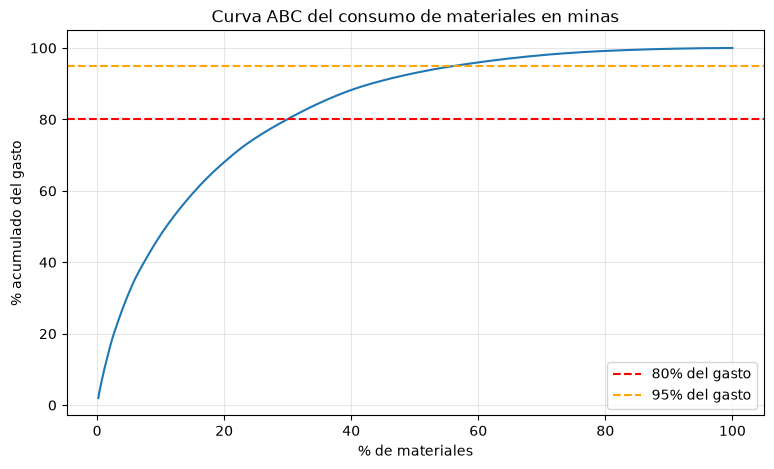

In [39]:
import matplotlib.pyplot as plt

# Para cada material: qué % de materiales llevamos recorrido (eje X)
consumo["pct_materiales"] = (consumo.index + 1) / len(consumo)

plt.figure(figsize=(9, 5))
plt.plot(consumo["pct_materiales"] * 100, consumo["pct_acum"] * 100)
plt.axhline(80, color="red", linestyle="--", label="80% del gasto")
plt.axhline(95, color="orange", linestyle="--", label="95% del gasto")
plt.xlabel("% de materiales")
plt.ylabel("% acumulado del gasto")
plt.title("Curva ABC del consumo de materiales en minas")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


# Análisis ABC del consumo de materiales

**Período analizado: octubre 2023 a septiembre 2026 · Base: despachos a mina (USD 136,7 M consumidos, 519 materiales)**

1. El gasto está concentrado, pero menos de lo habitual. 155 materiales (el 30% del total) explican el 80% del valor consumido. Es más que la referencia clásica del 20%, así que el almacén tiene más ítems que necesitan seguimiento cercano de lo que se suele esperar.

2. Clasificar solo por consumo es insuficiente y puede ser riesgoso. Nuestro ABC coincide solo en el 56% de los casos con la clasificación vigente, que también considera criticidad y costo unitario. El caso más claro es el MAT-00162 (componente de chancado, criticidad alta): no registra despachos en tres años, por lo que un ABC por consumo lo excluiría por completo. Se trata de un repuesto de seguro, y su falta podría detener la planta.

3. Encontramos 22 materiales “trampa”: consumo bajo (clase C) pero criticidad alta. Representan menos del 1% del gasto (USD 0,95 M), pero incluyen componentes de molienda, motores eléctricos de potencia, componentes hidráulicos mayores, variadores de frecuencia, componentes de chancado y equipos contra incendio. Por su bajo consumo, son los que con más facilidad quedan sin reposición.

4. Recomendaciones:
    - Gestionar los materiales con una matriz ABC × criticidad en lugar de usar solo el ABC.
    - Asignar a los 22 materiales trampa un stock mínimo obligatorio y una revisión mensual, independiente de su consumo.
    - Validar con Mantenimiento la lista de repuestos de seguro y su lead time de reposición.

# Quiebres De Stock

- Pregunta de Negocio: ¿En qué almacenes y con qué materiales nos quedamos sin stock? ¿Y cuántas de esas veces se trataba de un material crítico?

In [7]:
df[["movement_type","movement_direction","material_id","warehouse_name","stock_before","quantity","stock_after"]].head(10)

,movement_type,movement_direction,material_id,warehouse_name,stock_before,quantity,stock_after
0,Transferencia Salida,Salida,MAT-00004,Hub Regional NOA - Salta,143,31,112
1,Despacho a Mina,Salida,MAT-00009,Almacén de Sitio Salar Azul,17,8,9
2,Despacho a Mina,Salida,MAT-00020,Almacén de Sitio Cerro Blanco Norte,2,2,0
3,Despacho a Mina,Salida,MAT-00025,Almacén de Sitio Cordillera de Oro,13,6,7
4,Despacho a Mina,Salida,MAT-00026,Almacén de Sitio Cobre Andino,3,2,1
5,Despacho a Mina,Salida,MAT-00027,Almacén de Sitio Veta Dorada Sur,13,5,8
6,Despacho a Mina,Salida,MAT-00029,Almacén de Sitio Altos del Inca,10,2,8
7,Despacho a Mina,Salida,MAT-00041,Almacén de Sitio Cobre Andino,25,8,17
8,Transferencia Salida,Salida,MAT-00042,Hub Regional Cuyo - San Juan,5,2,3
9,Despacho a Mina,Salida,MAT-00048,Almacén de Sitio Quebrada del Sol,33,7,26


In [103]:
salidas = df[df["movement_direction"] == "Salida"]
salidas["diff"] = salidas["stock_before"] - salidas["quantity"] == salidas["stock_after"]
salidas[["material_id","diff"]].value_counts().head(10)

material_id  diff
MAT-00009    True    238
MAT-00419    True    238
MAT-00364    True    238
MAT-00295    True    237
MAT-00220    True    236
MAT-00340    True    236
MAT-00440    True    235
MAT-00436    True    234
MAT-00196    True    234
MAT-00030    True    234
Name: count, dtype: int64

In [100]:
quiebres = salidas[salidas["stock_after"] == 0]
resumen = pd.DataFrame({
    "Salidas totales": [len(salidas)],
    "Quiebres": [len(quiebres)],
    "% de salidas": [round(len(quiebres) / len(salidas) * 100, 1)]
})
resumen

,Salidas totales,Quiebres,% de salidas
0,81341,9331,11.5


In [101]:
quiebres["movement_type"].value_counts()

movement_type
Despacho a Mina           7288
Transferencia Salida      1990
Ajuste Negativo             43
Devolución a Proveedor      10
Name: count, dtype: int64

¿Qué porcentaje de las salidas deja el stock en cero? ¿Te parece mucho o poco para un almacén minero?

- El 11,5% de las salidas deja el stock en cero. La mediana del stock previo en esos casos es de solo 2 unidades, lo que indica niveles de stock muy ajustados.

  
¿Qué tipo de quiebre es más grave para la operación: el que viene de un Despacho a Mina o el de una Transferencia Salida? Pensá adónde va el material en cada caso.

- Los quiebres por transferencia se pueden reducir con una regla simple, como no transferir la última unidad de un material, mientras que los de despacho necesitan más stock de seguridad.